# Neurons — Simulação 1 | Análise fatorial

Notebook para ler **até 30 arquivos** `simulation_I_J_K_eta.neuronsim`, com `I ≥ J ≥ K`, dimensões em `{4,8,16}` e etiquetas `eta = 03, 05, 10`, correspondendo respectivamente a `0.3`, `0.5` e `1.0`.

**Escopo:** uma execução por configuração. Comparações são **descritivas**, sem inferência estatística de repetibilidade. As curvas representam **todos os arquivos carregados**, e o gráfico interativo permite selecionar quais mostrar.

**Importante:** o valor de `eta` será obtido **do nome do arquivo e conferido contra `external_parameters.connections_density`**; o leitor não presume que `experiment_parameters.mutation_probability` seja a mesma variável. `N=IJK` é o número de posições da malha, **não** o total comprovado de neurônios vivos. Os históricos registram apenas gerações concluídas.
**Desempenho:** quando disponíveis no resumo textual, `Neural iterations/s` e `Generation real time` são indicadores reportados no instante salvo, **não médias de todas as gerações evolutivas**. O tempo isolado de construção dos cérebros não consta do arquivo.


## 1. Configuração e dependências
Coloque este notebook, `read_neuronsim.py` e os arquivos `.neuronsim` na mesma pasta (ou ajuste `DATA_DIR` e `READER_DIR`). Execute as células de cima para baixo. Instale os pacotes se necessário: `pip install pandas numpy matplotlib ipywidgets`.

In [1]:
from pathlib import Path
import sys, re, json, hashlib, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('.').resolve()   # diretório contendo os .neuronsim
READER_DIR = Path('.').resolve() # diretório contendo read_neuronsim.py
EXPORT_DIR = Path('outputs_sim1')
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

if str(READER_DIR) not in sys.path:
    sys.path.insert(0, str(READER_DIR))
from read_neuronsim import load

DIMS = (4, 8, 16)
ETA_CODES = {'03': 0.3, '05': 0.5, '10': 1.0}
GEOMETRIES = [(i,j,k) for i in DIMS for j in DIMS for k in DIMS if i >= j >= k]
EXPECTED = {f'simulation_{i}_{j}_{k}_{eta}.neuronsim'
            for i,j,k in GEOMETRIES for eta in ETA_CODES}
FILENAME = re.compile(r'^simulation_(\d+)_(\d+)_(\d+)_(03|05|10)\.neuronsim$', re.IGNORECASE)
plt.rcParams['figure.figsize'] = (10,5)
plt.rcParams['axes.grid'] = True
print('Esperados:', len(EXPECTED), '| geometrias:', len(GEOMETRIES))

Esperados: 30 | geometrias: 10


## 2. Leitura, conferência de nomes e integridade
Arquivos fora do padrão são informados e ignorados. Dimensões internas divergentes, históricos de tamanhos diferentes e falhas de leitura são reportados.

In [2]:
def unique_genomes(genomes):
    hashes = set()
    for genome in genomes:
        canonical = json.dumps(genome, sort_keys=True, separators=(',', ':'), ensure_ascii=False)
        hashes.add(hashlib.sha256(canonical.encode('utf-8')).hexdigest())
    return len(hashes)

def safe_float(v):
    try: return float(v) if v is not None else np.nan
    except (ValueError, TypeError): return np.nan

def extract(path):
    m = FILENAME.fullmatch(path.name)
    if not m: raise ValueError('nome fora do padrão')
    i,j,k = map(int, m.group(1,2,3)); code = m.group(4)
    d = load(path)
    ext = d.get('external_parameters') or {}
    expp = d.get('experiment_parameters') or {}
    ev = d.get('evolution') or {}
    genomes = d.get('genomes') or []
    size = ext.get('size')
    size_vals = size.get('values') if isinstance(size, dict) else size
    if list(size_vals or []) != [i,j,k]:
        raise ValueError(f'dimensões internas {size_vals} não conferem com o nome {(i,j,k)}')
    mean = ev.get('mean_fitness_history') or []
    best = ev.get('best_fitness_history') or []
    div = ev.get('genetic_diversity_history') or []
    completed = int(ev.get('completed_generation_count', len(mean)))
    if len({len(mean),len(best),len(div),completed}) != 1:
        raise ValueError(f'históricos inconsistentes: média={len(mean)}, melhor={len(best)}, diversidade={len(div)}, concluídas={completed}')
    if not mean: raise ValueError('histórico vazio: nenhuma geração concluída')
    a = np.asarray(mean, dtype=float); z = np.asarray(best, dtype=float); v = np.asarray(div, dtype=float)
    if not all(np.isfinite(t).all() for t in (a,z,v)):
        raise ValueError('históricos contêm valores não finitos')
    density_saved = safe_float(ext.get('connections_density'))
    if not np.isfinite(density_saved) or not np.isclose(density_saved, ETA_CODES[code], atol=1e-6, rtol=0):
        raise ValueError(f'η do nome ({ETA_CODES[code]}) diverge de connections_density salvo ({density_saved})')
    # Indicadores de desempenho são capturas textuais no instante do salvamento,
    # e NÃO séries históricas de desempenho ou tempo de construção de cérebros.
    snapshot = str(d.get('summary') or '')
    def summary_number(pattern):
        found = re.search(pattern, snapshot, flags=re.IGNORECASE | re.MULTILINE)
        return safe_float(found.group(1)) if found else np.nan
    ips = summary_number(r'Neural\s+iterations/s\s*:\s*([0-9]+(?:\.[0-9]+)?)')
    gen_wall = summary_number(r'Generation\s+real\s+time\s*:\s*([0-9]+(?:\.[0-9]+)?)\s*s\b')
    snapshot_generation = int(ev.get('generation_number', 0))
    row = dict(file=path.name, I=i,J=j,K=k, N=i*j*k,eta=ETA_CODES[code],eta_code=code,
        neural_iterations_per_second_snapshot=ips,
        generation_real_time_seconds_snapshot=gen_wall,
        performance_snapshot_generation=snapshot_generation,
        geometry=f'{i}×{j}×{k}', run_id=f'{i}×{j}×{k} | η={ETA_CODES[code]:.1f}',
        completed_generations=completed, current_generation=ev.get('generation_number'),
        fitness_mean_final=a[-1], fitness_best_final=z[-1],
        fitness_mean_peak=float(a.max()), fitness_mean_peak_generation=int(a.argmax()+1),
        fitness_best_peak_in_history=float(z.max()),
        fitness_best_record=safe_float(ev.get('best_agent_fitness')),
        fitness_best_mean_record=safe_float(ev.get('best_mean_fitness')),
        fitness_mean_auc_normalized=float(a.mean()),
        diversity_initial=v[0],diversity_final=v[-1],diversity_min=float(v.min()),
        genetic_distinct=unique_genomes(genomes), genome_count=len(genomes),
        mutation_probability=safe_float(expp.get('mutation_probability')),
        brain_density=safe_float(ext.get('connections_density')),
        agent_count=ext.get('agent_count'), format_version=d.get('format_version'),
        gen_90=next((idx+1 for idx,val in enumerate(a) if val>=.9), np.nan),
        gen_95=next((idx+1 for idx,val in enumerate(a) if val>=.95), np.nan),
        gen_98=next((idx+1 for idx,val in enumerate(a) if val>=.98), np.nan),
    )
    traces = pd.DataFrame({'generation': np.arange(1,completed+1), 'fitness_mean':a,
                            'fitness_best':z,'genetic_diversity':v})
    for field in ('file','I','J','K','N','eta','eta_code','geometry','run_id'):
        traces[field] = row[field]
    return row, traces

available = sorted(DATA_DIR.glob('simulation_*.neuronsim'))
missing = sorted(EXPECTED - {f.name for f in available})
extra = sorted(f.name for f in available if f.name not in EXPECTED)
rows, traces, errors = [], [], []
for path in available:
    if path.name not in EXPECTED: continue
    try:
        row, trace = extract(path)
        rows.append(row); traces.append(trace)
    except Exception as exc:
        errors.append({'file':path.name, 'error':str(exc)})
summary = pd.DataFrame(rows)
history = pd.concat(traces, ignore_index=True) if traces else pd.DataFrame()
if not summary.empty:
    summary = summary.sort_values(['N','I','J','K','eta']).reset_index(drop=True)
    history = history.sort_values(['N','I','J','K','eta','generation']).reset_index(drop=True)
print(f'Encontrados: {len(available)} | carregados: {len(summary)}/{len(EXPECTED)} | faltantes: {len(missing)} | fora do padrão: {len(extra)} | erros: {len(errors)}')
if missing: print('Faltantes (primeiros 12):', missing[:12])
if extra: print('Nomes não esperados:', extra[:12])
if errors: display(pd.DataFrame(errors))
if not summary.empty:
    display(summary[['geometry','eta','completed_generations','fitness_mean_final','fitness_best_record','diversity_final']].head(10))
else:
    print('Nenhum arquivo válido carregado. Coloque os arquivos em DATA_DIR e execute novamente.')

Encontrados: 30 | carregados: 30/30 | faltantes: 0 | fora do padrão: 0 | erros: 0


,geometry,eta,completed_generations,fitness_mean_final,fitness_best_record,diversity_final
0,4×4×4,0.3,96,0.962231,0.998762,0.056450
1,4×4×4,0.5,95,0.969067,0.998013,0.051833
2,4×4×4,1.0,95,0.968568,0.996703,0.047182
3,8×4×4,0.3,94,0.975138,0.998555,0.041966
4,8×4×4,0.5,94,0.903019,0.989278,0.061872
5,8×4×4,1.0,93,0.968384,0.993258,0.055367
6,8×8×4,0.3,96,0.954863,0.998387,0.063597
7,8×8×4,0.5,93,0.868709,0.985105,0.055944
8,8×8×4,1.0,94,0.969399,0.997547,0.051016
9,16×4×4,0.3,96,0.933520,0.998311,0.061187


## 3. Tabela geral, ranking e matrizes de completude
As comparações usam uma linha por execução. As classificações não medem significância estatística.

In [3]:
if not summary.empty:
    cols = ['geometry','N','eta','completed_generations','fitness_mean_final',
            'fitness_mean_peak','fitness_best_final','fitness_best_record',
            'fitness_mean_auc_normalized','gen_90','gen_95','gen_98',
            'diversity_final','genetic_distinct','genome_count']
    display(summary[cols].round(5))
    print('Top 15 — fitness média final')
    display(summary.nlargest(15, 'fitness_mean_final')[cols].round(5))
    print('Top 15 — melhor fitness individual histórica')
    display(summary.nlargest(15, 'fitness_best_record')[cols].round(5))
    complete = pd.DataFrame({'geometry':[f'{i}×{j}×{k}' for i,j,k in GEOMETRIES]})
    for e in ETA_CODES.values():
        complete[f'η={e:g}'] = complete.geometry.isin(summary.loc[summary.eta==e,'geometry']).map({True:'✓',False:'—'})
    display(complete)


,geometry,N,eta,completed_generations,fitness_mean_final,fitness_mean_peak,fitness_best_final,fitness_best_record,fitness_mean_auc_normalized,gen_90,gen_95,gen_98,diversity_final,genetic_distinct,genome_count
0,4×4×4,64,0.3,96,0.96223,0.98563,0.99330,0.99876,0.94081,1,16,52.0,0.05645,100,100
1,4×4×4,64,0.5,95,0.96907,0.98748,0.99470,0.99801,0.93255,9,9,38.0,0.05183,99,100
2,4×4×4,64,1.0,95,0.96857,0.98976,0.99159,0.99670,0.93543,1,1,63.0,0.04718,95,100
3,8×4×4,128,0.3,94,0.97514,0.99263,0.99434,0.99855,0.95045,7,14,25.0,0.04197,95,100
4,8×4×4,128,0.5,94,0.90302,0.97019,0.96177,0.98928,0.88838,1,37,NaN,0.06187,99,100
5,8×4×4,128,1.0,93,0.96838,0.97654,0.98687,0.99326,0.91174,5,24,NaN,0.05537,98,100
6,8×8×4,256,0.3,96,0.95486,0.98728,0.98797,0.99839,0.88337,35,53,85.0,0.06360,100,100
7,8×8×4,256,0.5,93,0.86871,0.97426,0.91114,0.98511,0.88560,16,40,NaN,0.05594,96,100
8,8×8×4,256,1.0,94,0.96940,0.98037,0.99579,0.99755,0.94291,9,15,81.0,0.05102,100,100
9,16×4×4,256,0.3,96,0.93352,0.97964,0.98790,0.99831,0.93507,2,14,NaN,0.06119,98,100


Top 15 — fitness média final


,geometry,N,eta,completed_generations,fitness_mean_final,fitness_mean_peak,fitness_best_final,fitness_best_record,fitness_mean_auc_normalized,gen_90,gen_95,gen_98,diversity_final,genetic_distinct,genome_count
16,16×8×4,512,0.5,97,0.98211,0.99164,0.99475,0.99670,0.95636,9,18,23.0,0.02895,95,100
29,16×16×16,4096,1.0,98,0.97811,0.99008,0.99501,0.99779,0.95610,3,13,40.0,0.04499,99,100
3,8×4×4,128,0.3,94,0.97514,0.99263,0.99434,0.99855,0.95045,7,14,25.0,0.04197,95,100
18,16×8×8,1024,0.3,96,0.97485,0.98794,0.99509,0.99779,0.92408,7,22,75.0,0.05072,100,100
14,8×8×8,512,1.0,96,0.97208,0.99428,0.99207,0.99809,0.93414,1,1,63.0,0.04641,100,100
25,16×16×8,2048,0.5,98,0.97128,0.97999,0.99083,0.99478,0.90252,15,34,NaN,0.04466,95,100
13,8×8×8,512,0.5,95,0.97068,0.98585,0.98976,0.99543,0.90752,1,20,46.0,0.06497,100,100
8,8×8×4,256,1.0,94,0.96940,0.98037,0.99579,0.99755,0.94291,9,15,81.0,0.05102,100,100
1,4×4×4,64,0.5,95,0.96907,0.98748,0.99470,0.99801,0.93255,9,9,38.0,0.05183,99,100
17,16×8×4,512,1.0,95,0.96884,0.98254,0.99704,0.99887,0.94026,10,20,67.0,0.04850,99,100


Top 15 — melhor fitness individual histórica


,geometry,N,eta,completed_generations,fitness_mean_final,fitness_mean_peak,fitness_best_final,fitness_best_record,fitness_mean_auc_normalized,gen_90,gen_95,gen_98,diversity_final,genetic_distinct,genome_count
17,16×8×4,512,1.0,95,0.96884,0.98254,0.99704,0.99887,0.94026,10,20,67.0,0.04850,99,100
21,16×16×4,1024,0.3,96,0.96731,0.98282,0.99342,0.99886,0.93074,11,23,50.0,0.04743,98,100
23,16×16×4,1024,1.0,103,0.94047,0.97996,0.99137,0.99879,0.93324,5,21,NaN,0.05509,99,100
0,4×4×4,64,0.3,96,0.96223,0.98563,0.99330,0.99876,0.94081,1,16,52.0,0.05645,100,100
10,16×4×4,256,0.5,100,0.94288,0.98375,0.99248,0.99858,0.92652,3,23,26.0,0.05324,98,100
3,8×4×4,128,0.3,94,0.97514,0.99263,0.99434,0.99855,0.95045,7,14,25.0,0.04197,95,100
6,8×8×4,256,0.3,96,0.95486,0.98728,0.98797,0.99839,0.88337,35,53,85.0,0.06360,100,100
27,16×16×16,4096,0.3,96,0.94101,0.98614,0.99032,0.99832,0.94458,1,19,89.0,0.06666,100,100
9,16×4×4,256,0.3,96,0.93352,0.97964,0.98790,0.99831,0.93507,2,14,NaN,0.06119,98,100
11,16×4×4,256,1.0,96,0.95433,0.98736,0.99260,0.99825,0.94318,15,19,48.0,0.04880,99,100


,geometry,η=0.3,η=0.5,η=1
0,4×4×4,✓,✓,✓
1,8×4×4,✓,✓,✓
2,8×8×4,✓,✓,✓
3,8×8×8,✓,✓,✓
4,16×4×4,✓,✓,✓
5,16×8×4,✓,✓,✓
6,16×8×8,✓,✓,✓
7,16×16×4,✓,✓,✓
8,16×16×8,✓,✓,✓
9,16×16×16,✓,✓,✓


## 4. Evolução — todas as curvas, com filtros interativos
O gráfico inclui **uma curva por arquivo**, sem agregação. Se `ipywidgets` estiver disponível, escolha subconjuntos por geometria, `η` e métrica. Na legenda do Matplotlib, o texto identifica cada configuração. Sem widgets, o notebook desenha todas as curvas disponíveis.

In [4]:
def plot_evolution(selected=None, metric='fitness_mean', max_generation=None, legend=True):
    if history.empty:
        print('Sem dados.'); return
    df = history if selected is None else history.loc[history.run_id.isin(selected)]
    if max_generation is not None: df = df.loc[df.generation<=max_generation]
    fig, ax = plt.subplots(figsize=(13,7))
    for name, part in df.groupby('run_id',sort=False):
        ax.plot(part.generation, part[metric],lw=1.4,alpha=.82,label=name)
    ax.set(xlabel='Geração concluída',ylabel={'fitness_mean':'Fitness média','fitness_best':'Melhor fitness por geração','genetic_diversity':'Diversidade genética'}[metric],
           title=f'Evolução individual — {df.run_id.nunique()} curvas')
    if legend and df.run_id.nunique():
        ax.legend(fontsize=7, ncol=3, bbox_to_anchor=(1.02,1),loc='upper left')
    plt.tight_layout();plt.show()

if not summary.empty:
    try:
        import ipywidgets as widgets
        from IPython.display import clear_output
        i_options = sorted(summary.geometry.unique(),key=lambda s: tuple(-int(v) for v in s.split('×')))
        geom = widgets.SelectMultiple(options=i_options,value=tuple(i_options),description='Geometrias',rows=min(12,len(i_options)),layout=widgets.Layout(width='220px'))
        etas = widgets.SelectMultiple(options=[(f'{e:.1f}',e) for e in sorted(summary.eta.unique())],value=tuple(sorted(summary.eta.unique())),description='η',rows=4,layout=widgets.Layout(width='180px'))
        metric = widgets.Dropdown(options=[('Fitness média','fitness_mean'),('Melhor fitness','fitness_best'),('Diversidade','genetic_diversity')],description='Métrica')
        maxgen = widgets.IntSlider(value=int(history.generation.max()),min=1,max=int(history.generation.max()),description='Até geração',continuous_update=False,layout=widgets.Layout(width='420px'))
        showlegend = widgets.Checkbox(value=True,description='Mostrar legenda')
        out = widgets.Output()
        def refresh(change=None):
            selected = summary.loc[summary.geometry.isin(geom.value) & summary.eta.isin(etas.value),'run_id'].tolist()
            with out:
                clear_output(wait=True)
                plot_evolution(selected,metric.value,maxgen.value,showlegend.value)
        for w in (geom,etas,metric,maxgen,showlegend):w.observe(refresh,names='value')
        display(widgets.VBox([widgets.HBox([geom,etas,widgets.VBox([metric,maxgen,showlegend])]),out]))
        refresh()
    except ImportError:
        print('ipywidgets não disponível: exibindo todas as curvas.')
        plot_evolution()


## 5. Fitness × tamanho da malha
Todas as configurações são mostradas, diferenciando `η`. Assim, geometrias com o mesmo N permanecem visíveis como pontos distintos (um leve deslocamento horizontal evita sobreposição).

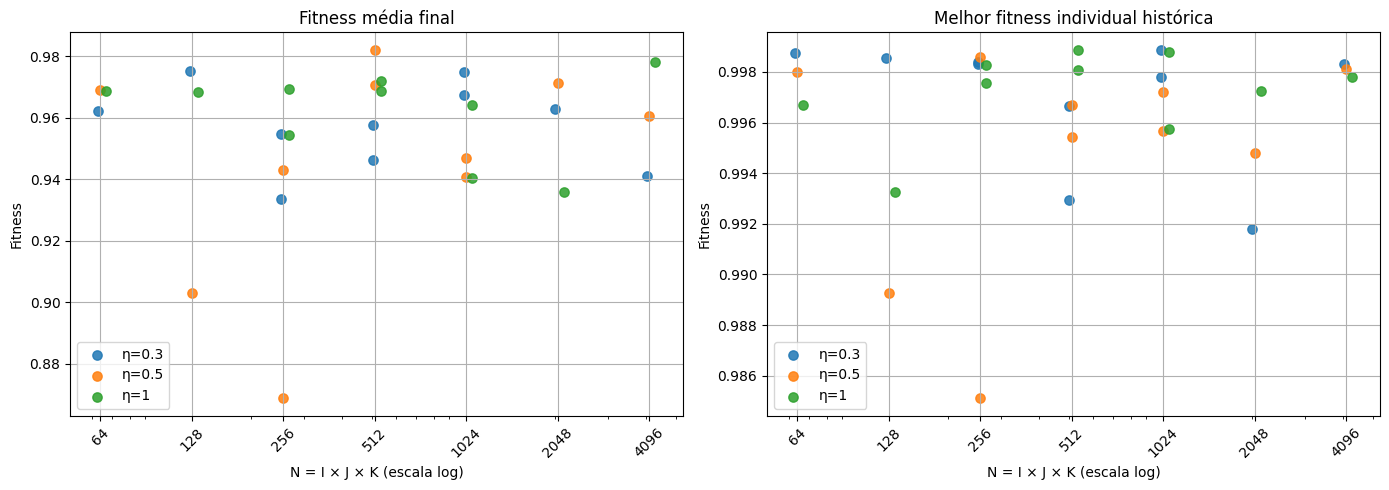

In [5]:
if not summary.empty:
    fig,axs=plt.subplots(1,2,figsize=(14,5))
    for eta,df in summary.groupby('eta'):
        for ax,metric in zip(axs,['fitness_mean_final','fitness_best_record']):
            ax.scatter(df.N*(1+(eta-.5)*.09),df[metric],alpha=.85,s=45,label=f'η={eta:g}')
    for ax,title in zip(axs,['Fitness média final','Melhor fitness individual histórica']):
        ax.set(xscale='log',xlabel='N = I × J × K (escala log)',ylabel='Fitness',title=title)
        ax.set_xticks(sorted(summary.N.unique()))
        ax.set_xticklabels(sorted(summary.N.unique()),rotation=45)
        ax.legend()
    plt.tight_layout();plt.show()


## 6. Heatmaps: geometria × η
As células são as execuções efetivamente carregadas. Ausências ficam vazias; as linhas estão ordenadas por N e dimensões.

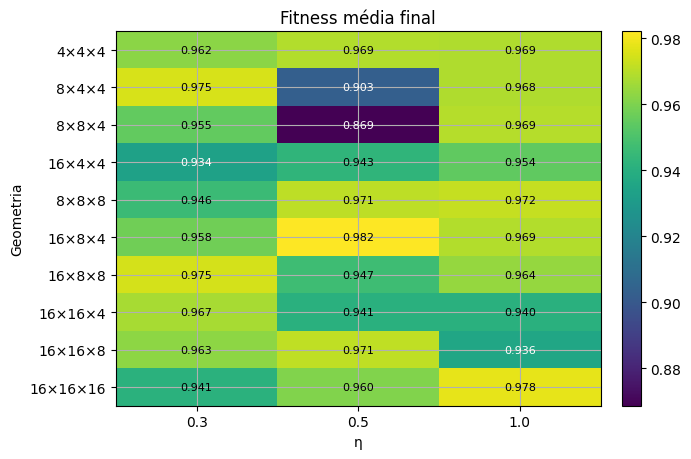

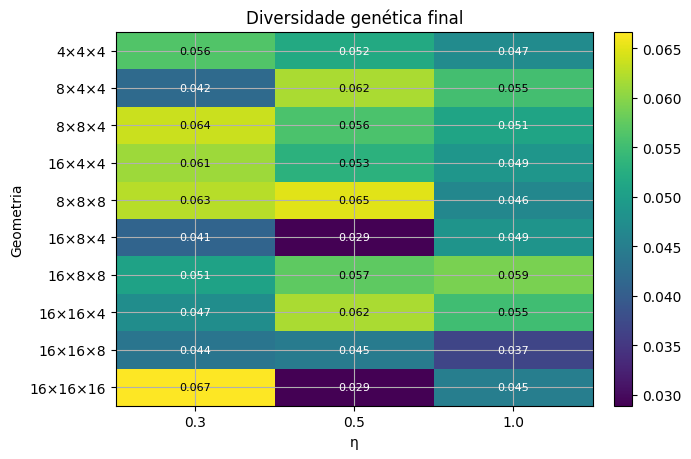

eta,0.3,0.5,1.0
geometry,,,
4×4×4,0.96223,0.96907,0.96857
8×4×4,0.97514,0.90302,0.96838
8×8×4,0.95486,0.86871,0.96940
16×4×4,0.93352,0.94288,0.95433
8×8×8,0.94620,0.97068,0.97208
16×8×4,0.95766,0.98211,0.96884
16×8×8,0.97485,0.94686,0.96401
16×16×4,0.96731,0.94068,0.94047
16×16×8,0.96272,0.97128,0.93576


In [6]:
def heatmap_metric(metric, title, fmt='.3f'):
    if summary.empty:return
    table = summary.pivot(index='geometry',columns='eta',values=metric)
    ordered = summary.sort_values(['N','I','J','K']).geometry.drop_duplicates().tolist()
    table = table.reindex(ordered)
    vals=table.to_numpy(dtype=float)
    fig,ax=plt.subplots(figsize=(7,max(4,len(table)*.37+1)))
    img=ax.imshow(np.ma.masked_invalid(vals),aspect='auto',cmap='viridis')
    ax.set_xticks(range(len(table.columns)),[f'{x:.1f}' for x in table.columns]);ax.set_yticks(range(len(table)),table.index)
    ax.set(xlabel='η',ylabel='Geometria',title=title)
    for y in range(vals.shape[0]):
        for x in range(vals.shape[1]):
            if np.isfinite(vals[y,x]): ax.text(x,y,format(vals[y,x],fmt),ha='center',va='center',fontsize=8,
              color='black' if (vals[y,x]-np.nanmin(vals))/(max(np.nanmax(vals)-np.nanmin(vals),1e-12))>.62 else 'white')
    fig.colorbar(img,ax=ax,fraction=.046,pad=.04);plt.tight_layout();plt.show()
    return table

if not summary.empty:
    fitness_heatmap = heatmap_metric('fitness_mean_final','Fitness média final')
    diversity_heatmap = heatmap_metric('diversity_final','Diversidade genética final')
    display(fitness_heatmap.round(5))


## 7. Comparação de geometrias com mesmo N
O gráfico abaixo mantém explícitos os casos com tamanho da malha idêntico, permitindo avaliar diferenças associadas à geometria — sem afirmar causalidade.

,N,geometry,eta,fitness_mean_final,fitness_best_record
9,256,16×4×4,0.3,0.93352,0.99831
6,256,8×8×4,0.3,0.95486,0.99839
10,256,16×4×4,0.5,0.94288,0.99858
7,256,8×8×4,0.5,0.86871,0.98511
11,256,16×4×4,1.0,0.95433,0.99825
8,256,8×8×4,1.0,0.96940,0.99755
15,512,16×8×4,0.3,0.95766,0.99667
12,512,8×8×8,0.3,0.94620,0.99295
16,512,16×8×4,0.5,0.98211,0.99670
13,512,8×8×8,0.5,0.97068,0.99543


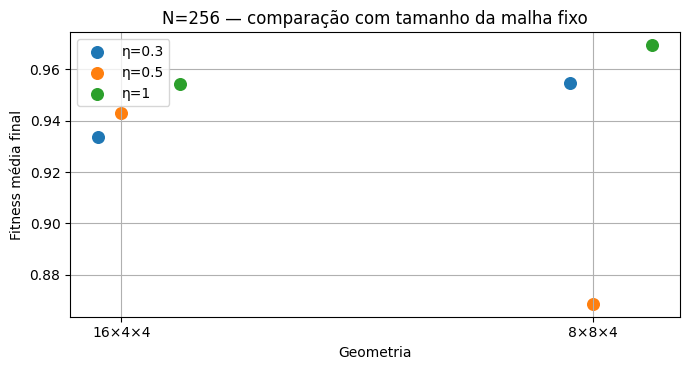

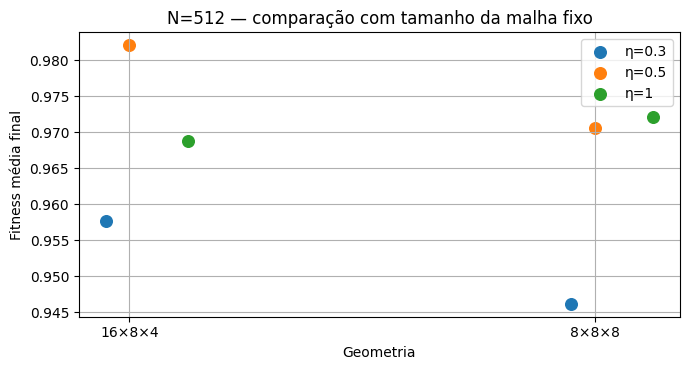

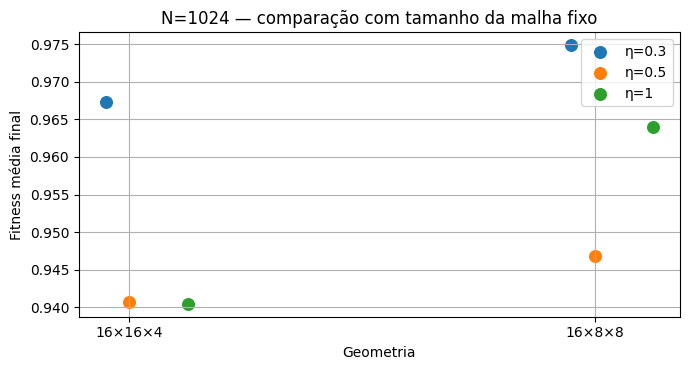

In [7]:
if not summary.empty:
    counts=summary[['N','geometry']].drop_duplicates().groupby('N').size()
    eligible=counts[counts>1].index
    display(summary.loc[summary.N.isin(eligible),['N','geometry','eta','fitness_mean_final','fitness_best_record']].sort_values(['N','eta','geometry']).round(5))
    for size in eligible:
        df=summary.loc[summary.N==size]
        fig,ax=plt.subplots(figsize=(max(7,len(df.geometry.unique())*1.5),3.8))
        geoms=sorted(df.geometry.unique())
        for eta,part in df.groupby('eta'):
            mapping={v:i for i,v in enumerate(geoms)}
            ax.scatter([mapping[g] + (eta-0.5)*.25 for g in part.geometry],part.fitness_mean_final,s=70,label=f'η={eta:g}')
        ax.set_xticks(range(len(geoms)),geoms)
        ax.set(ylabel='Fitness média final',xlabel='Geometria',title=f'N={size} — comparação com tamanho da malha fixo')
        ax.legend();plt.tight_layout();plt.show()


## 8. Velocidade evolutiva e diversidade
`gen_90`, `gen_95` e `gen_98` são a **primeira geração em que a FITNESS MÉDIA** atinge o limiar; valores ausentes indicam que o limiar não foi alcançado. Com números de gerações desiguais, comparar a média de toda a trajetória também requer cautela.

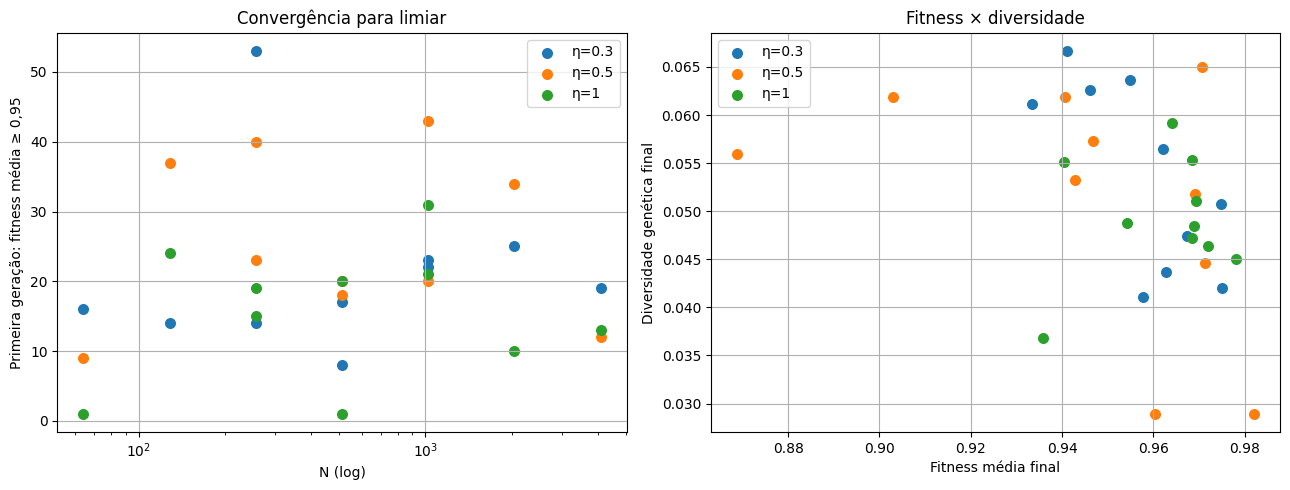

,geometry,eta,completed_generations,gen_90,gen_95,gen_98
2,4×4×4,1.0,95,1,1,63.0
14,8×8×8,1.0,96,1,1,63.0
12,8×8×8,0.3,94,2,8,NaN
1,4×4×4,0.5,95,9,9,38.0
26,16×16×8,1.0,97,10,10,37.0
28,16×16×16,0.5,97,3,12,14.0
29,16×16×16,1.0,98,3,13,40.0
3,8×4×4,0.3,94,7,14,25.0
9,16×4×4,0.3,96,2,14,NaN
8,8×8×4,1.0,94,9,15,81.0


In [8]:
if not summary.empty:
    fig,axs=plt.subplots(1,2,figsize=(13,5))
    for eta,part in summary.groupby('eta'):
        axs[0].scatter(part.N,part.gen_95,label=f'η={eta:g}',s=48)
        axs[1].scatter(part.fitness_mean_final,part.diversity_final,label=f'η={eta:g}',s=48)
    axs[0].set(xscale='log',xlabel='N (log)',ylabel='Primeira geração: fitness média ≥ 0,95',title='Convergência para limiar')
    axs[1].set(xlabel='Fitness média final',ylabel='Diversidade genética final',title='Fitness × diversidade')
    for ax in axs:ax.legend()
    plt.tight_layout();plt.show()
    display(summary[['geometry','eta','completed_generations','gen_90','gen_95','gen_98']].sort_values('gen_95',na_position='last'))


## 9. Efeito descritivo de η e ranking de eficiência
A tabela abaixo agrega **geometrias diferentes** e não deve ser interpretada como efeito isolado de η. O segundo quadro compara η **dentro de cada geometria** e só exibe casos com as três execuções carregadas.

In [9]:
if not summary.empty:
    cols=['fitness_mean_final','fitness_best_record','diversity_final','fitness_mean_auc_normalized','genetic_distinct']
    display(summary.groupby('eta')[cols].agg(['count','mean','median','min','max']).round(5))
    p=summary.pivot(index='geometry',columns='eta',values='fitness_mean_final')
    if {0.3,0.5,1.0}.issubset(p.columns):
        paired=p.dropna(subset=[0.3,0.5,1.0]).copy()
        paired['Δ(0.5-0.3)']=paired[0.5]-paired[0.3]
        paired['Δ(1.0-0.3)']=paired[1.0]-paired[0.3]
        display(paired.round(5))
    else:print('Comparação pareada incompleta: faltam valores de η.')


fitness_mean_final                                      \
                 count     mean   median      min      max   
eta                                                          
0.3                 10  0.95755  0.95994  0.93352  0.97514   
0.5                 10  0.94557  0.95365  0.86871  0.98211   
1.0                 10  0.96199  0.96848  0.93576  0.97811   

    fitness_best_record                                      ...  \
                  count     mean   median      min      max  ...   
eta                                                          ...   
0.3                  10  0.99704  0.99832  0.99178  0.99886  ...   
0.5                  10  0.99489  0.99619  0.98511  0.99858  ...   
1.0                  10  0.99723  0.99767  0.99326  0.99887  ...   

    fitness_mean_auc_normalized                                      \
                          count     mean   median      min      max   
eta                                                                   
0.3                          10  0.92815  0.93290  0.88337  0.95045   
0.5                          10  0.92227  0.92615  0.88560  0.95838   
1.0                          10  0.93219  0.93479  0.91128  0.95610   

    genetic_distinct                        
               count  mean median min  max  
eta                                         
0.3               10  98.4   99.0  95  100  
0.5               10  97.0   98.0  90  100  
1.0               10  98.8   99.0  95  100  

[3 rows x 25 columns]

eta,0.3,0.5,1.0,Δ(0.5-0.3),Δ(1.0-0.3)
geometry,,,,,
16×16×16,0.94101,0.96043,0.97811,0.01942,0.03709
16×16×4,0.96731,0.94068,0.94047,-0.02663,-0.02684
16×16×8,0.96272,0.97128,0.93576,0.00857,-0.02696
16×4×4,0.93352,0.94288,0.95433,0.00936,0.02081
16×8×4,0.95766,0.98211,0.96884,0.02445,0.01118
16×8×8,0.97485,0.94686,0.96401,-0.02799,-0.01084
4×4×4,0.96223,0.96907,0.96857,0.00684,0.00634
8×4×4,0.97514,0.90302,0.96838,-0.07212,-0.00675
8×8×4,0.95486,0.86871,0.96940,-0.08615,0.01454


## 10. Densidade configurada (η) × resultados evolutivos

`η` é lido do nome e **validado contra `external_parameters.connections_density`**. Ele representa a **densidade configurada**, não a fração de conexões efetivamente construídas.

O `.neuronsim` deste experimento contém genomas e históricos evolutivos, mas **não armazena as listas de sinapses nem o número de conexões dos fenótipos**. Portanto, não podemos calcular o grau médio, o total de conexões ou a densidade efetiva \(E/[N(N-1)]\) a partir dos dados disponíveis. Não estimamos esses números a partir de η.

Os gráficos abaixo distinguem geometria e tamanho da malha para investigar a associação entre η e os resultados, sem atribuir causalidade a uma única execução.


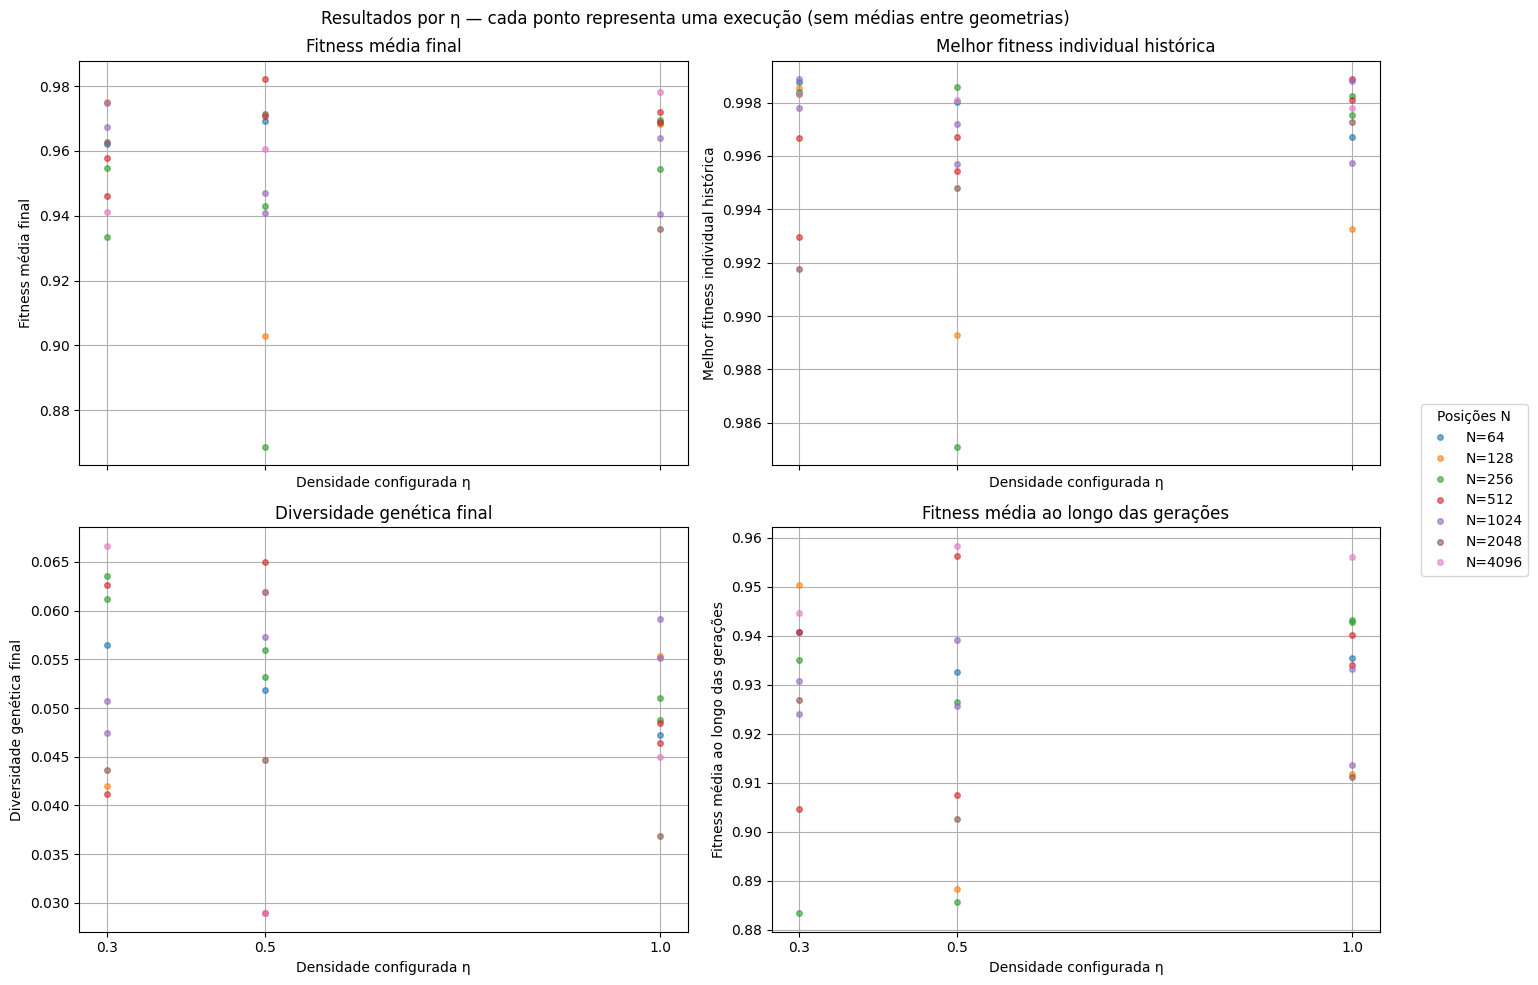

,geometry,N,eta,brain_density,fitness_mean_final,fitness_best_record,diversity_final
0,4×4×4,64,0.3,0.3,0.96223,0.99876,0.05645
1,4×4×4,64,0.5,0.5,0.96907,0.99801,0.05183
2,4×4×4,64,1.0,1.0,0.96857,0.99670,0.04718
3,8×4×4,128,0.3,0.3,0.97514,0.99855,0.04197
4,8×4×4,128,0.5,0.5,0.90302,0.98928,0.06187
5,8×4×4,128,1.0,1.0,0.96838,0.99326,0.05537
9,16×4×4,256,0.3,0.3,0.93352,0.99831,0.06119
10,16×4×4,256,0.5,0.5,0.94288,0.99858,0.05324
11,16×4×4,256,1.0,1.0,0.95433,0.99825,0.04880
6,8×8×4,256,0.3,0.3,0.95486,0.99839,0.06360


In [10]:
if not summary.empty:
    metrics = [('fitness_mean_final','Fitness média final'),
               ('fitness_best_record','Melhor fitness individual histórica'),
               ('diversity_final','Diversidade genética final'),
               ('fitness_mean_auc_normalized','Fitness média ao longo das gerações')]
    fig, axs = plt.subplots(2,2,figsize=(14,10),sharex=True)
    for ax,(metric,title) in zip(axs.flat,metrics):
        for n,grp in summary.groupby('N'):
            ax.plot(grp.eta,grp[metric], 'o', markersize=4, alpha=.60,
                    label=f'N={n}' if metric==metrics[0][0] else None)
        ax.set(title=title,xlabel='Densidade configurada η',ylabel=title,
               xticks=sorted(ETA_CODES.values()))
    handles,labels=axs.flat[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='center right',bbox_to_anchor=(1.10,.5),title='Posições N')
    fig.suptitle('Resultados por η — cada ponto representa uma execução (sem médias entre geometrias)')
    plt.tight_layout();plt.show()
    cols=['geometry','N','eta','brain_density','fitness_mean_final','fitness_best_record','diversity_final']
    display(summary[cols].sort_values(['N','geometry','eta']).round(5))


## 11. Contrastes pareados por geometria (η = 0,1 / 0,5 / 1,0)

Compara valores de η **na mesma geometria**, evitando confundir variações de densidade configurada com o número de posições. Diferenças observadas **não são estimativas robustas de efeito**, pois cada configuração possui somente uma execução e pode ter históricos com quantidades diferentes de gerações. A interpretação mais justa pressupõe mesmo orçamento evolutivo.


Fitness média final — geometria pareada


eta                0.3      0.5      1.0  Δ 0,5−0,1  Δ 1,0−0,1
N    geometry                                                 
64   4×4×4     0.96223  0.96907  0.96857    0.00684    0.00634
128  8×4×4     0.97514  0.90302  0.96838   -0.07212   -0.00675
256  16×4×4    0.93352  0.94288  0.95433    0.00936    0.02081
     8×8×4     0.95486  0.86871  0.96940   -0.08615    0.01454
512  16×8×4    0.95766  0.98211  0.96884    0.02445    0.01118
     8×8×8     0.94620  0.97068  0.97208    0.02448    0.02588
1024 16×16×4   0.96731  0.94068  0.94047   -0.02663   -0.02684
     16×8×8    0.97485  0.94686  0.96401   -0.02799   -0.01084
2048 16×16×8   0.96272  0.97128  0.93576    0.00857   -0.02696
4096 16×16×16  0.94101  0.96043  0.97811    0.01942    0.03709

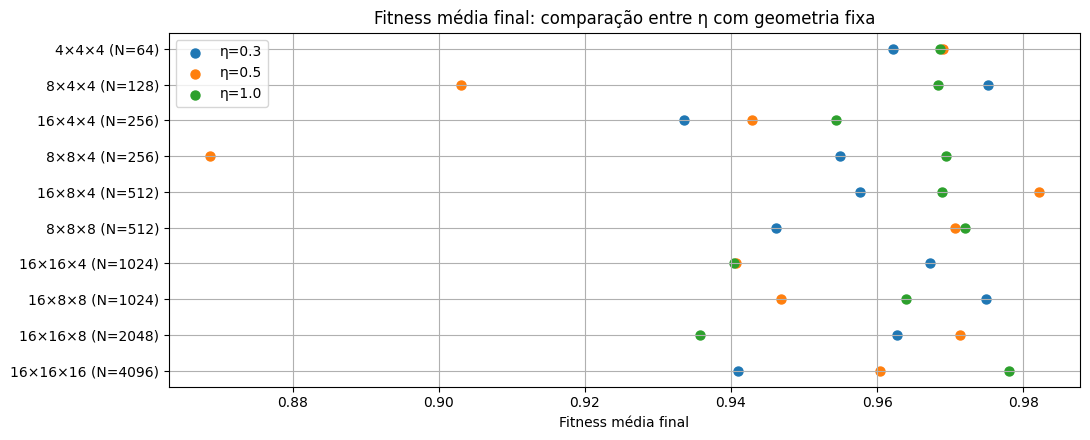

Melhor fitness individual histórica — geometria pareada


eta                0.3      0.5      1.0  Δ 0,5−0,1  Δ 1,0−0,1
N    geometry                                                 
64   4×4×4     0.99876  0.99801  0.99670   -0.00075   -0.00206
128  8×4×4     0.99855  0.98928  0.99326   -0.00928   -0.00530
256  16×4×4    0.99831  0.99858  0.99825    0.00027   -0.00006
     8×8×4     0.99839  0.98511  0.99755   -0.01328   -0.00084
512  16×8×4    0.99667  0.99670  0.99887    0.00004    0.00221
     8×8×8     0.99295  0.99543  0.99809    0.00248    0.00513
1024 16×16×4   0.99886  0.99568  0.99879   -0.00318   -0.00007
     16×8×8    0.99779  0.99721  0.99575   -0.00057   -0.00204
2048 16×16×8   0.99178  0.99478  0.99726    0.00300    0.00548
4096 16×16×16  0.99832  0.99810  0.99779   -0.00022   -0.00054

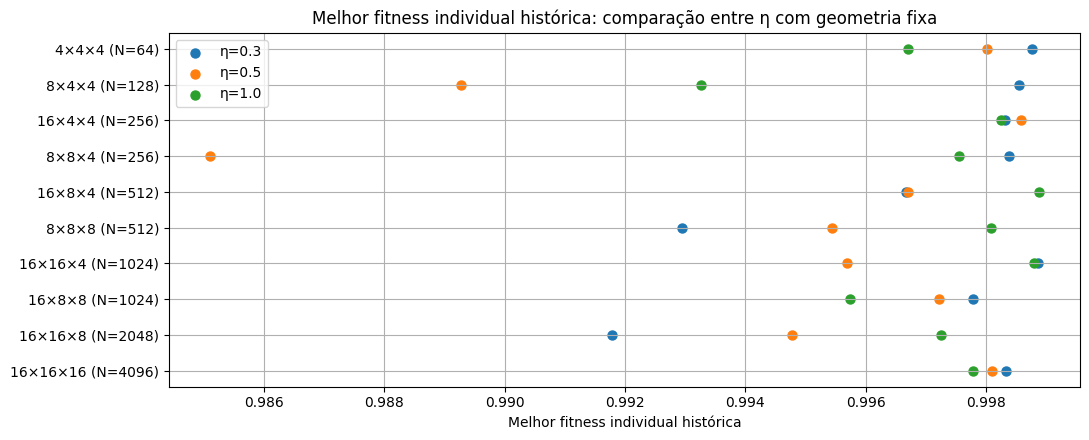

Diversidade genética final — geometria pareada


eta                0.3      0.5      1.0  Δ 0,5−0,1  Δ 1,0−0,1
N    geometry                                                 
64   4×4×4     0.05645  0.05183  0.04718   -0.00462   -0.00927
128  8×4×4     0.04197  0.06187  0.05537    0.01991    0.01340
256  16×4×4    0.06119  0.05324  0.04880   -0.00795   -0.01239
     8×8×4     0.06360  0.05594  0.05102   -0.00765   -0.01258
512  16×8×4    0.04112  0.02895  0.04850   -0.01217    0.00738
     8×8×8     0.06264  0.06497  0.04641    0.00233   -0.01623
1024 16×16×4   0.04743  0.06191  0.05509    0.01448    0.00766
     16×8×8    0.05072  0.05729  0.05912    0.00657    0.00840
2048 16×16×8   0.04365  0.04466  0.03681    0.00101   -0.00684
4096 16×16×16  0.06666  0.02891  0.04499   -0.03775   -0.02167

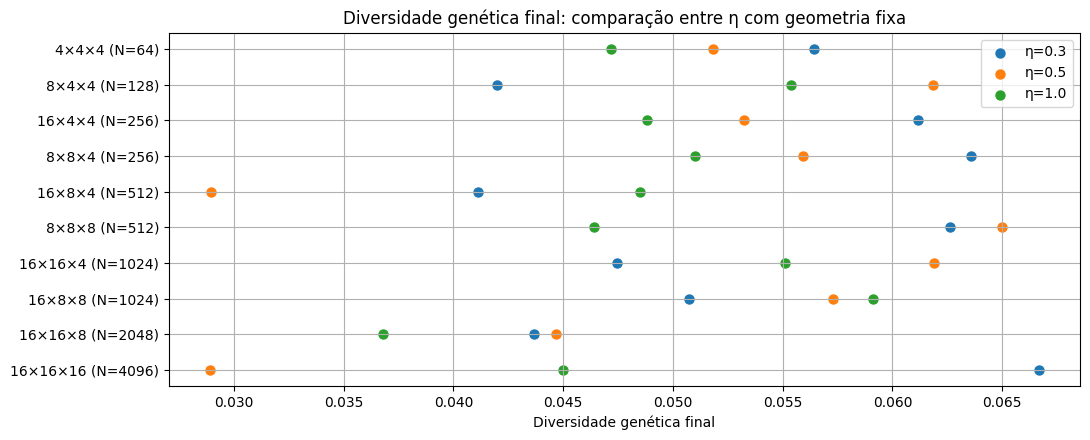

In [11]:
if not summary.empty:
    for metric, label in [('fitness_mean_final','Fitness média final'),
                          ('fitness_best_record','Melhor fitness individual histórica'),
                          ('diversity_final','Diversidade genética final')]:
        p = summary.pivot(index=['N','geometry'],columns='eta',values=metric)
        if {0.3,0.5,1.0}.issubset(p.columns):
            q = p.dropna(subset=[0.3,0.5,1.0]).copy()
            if not q.empty:
                q['Δ 0,5−0,1'] = q[0.5]-q[0.3]
                q['Δ 1,0−0,1'] = q[1.0]-q[0.3]
                print(label, '— geometria pareada')
                display(q.round(5))
                fig,ax=plt.subplots(figsize=(11,max(3.5,.35*len(q)+1)))
                for eta in [0.3,0.5,1.0]:
                    ax.scatter(q[eta],range(len(q)),label=f'η={eta:.1f}',s=42)
                ax.set_yticks(range(len(q)),[f'{geo} (N={n})' for n,geo in q.index]);ax.invert_yaxis()
                ax.set(xlabel=label,title=f'{label}: comparação entre η com geometria fixa')
                ax.legend();plt.tight_layout();plt.show()
        else:
            print(f'{label}: faltam execuções para contraste entre três valores de η.')


## 12. Desempenho computacional — medições disponíveis no arquivo

O campo textual `summary` registra, quando presente:

- **`Neural iterations/s`**: taxa reportada durante o estado salvo. Não é uma média das gerações do experimento.
- **`Generation real time`**: tempo real reportado para a **geração evolutiva** no resumo salvo. Não é o tempo específico da construção dos agentes/cérebros e não deve ser usado como tal. Dependendo do instante do salvamento, pode representar um valor de uma geração evolutiva ainda em andamento ou um indicador acumulado da cena.

Os gráficos seguintes comparam os valores **reportados**, sem reconstruir séries inexistentes. Valores não informados são tratados como ausentes, sem imputação. As diferenças também podem refletir condições de hardware, carga e momento do salvamento; faça os salvamentos em estágios comparáveis.


,geometry,N,eta,completed_generations,geracao_evolutiva_registrada,neural_iterations_per_second_snapshot,tempo_real_geracao_evolutiva_s_snapshot
0,4×4×4,64,0.3,96,97,0.0,1.984
1,4×4×4,64,0.5,95,96,0.0,2.076
2,4×4×4,64,1.0,95,96,0.0,2.261
3,8×4×4,128,0.3,94,95,0.0,1.973
4,8×4×4,128,0.5,94,95,0.0,1.476
5,8×4×4,128,1.0,93,94,0.0,3.040
9,16×4×4,256,0.3,96,96,NaN,NaN
10,16×4×4,256,0.5,100,101,0.0,5.617
11,16×4×4,256,1.0,96,96,NaN,NaN
6,8×8×4,256,0.3,96,97,0.0,1.742


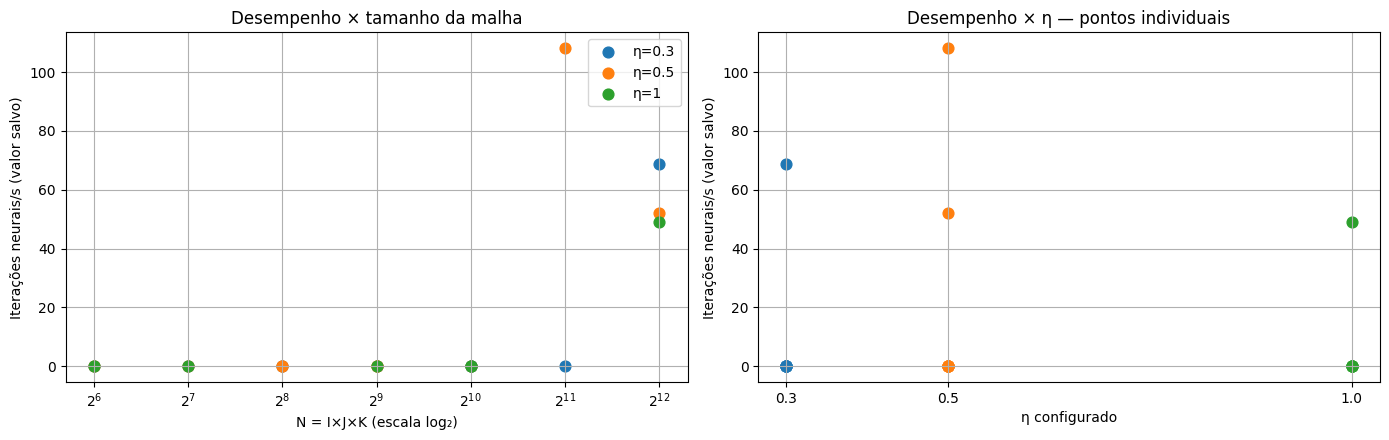

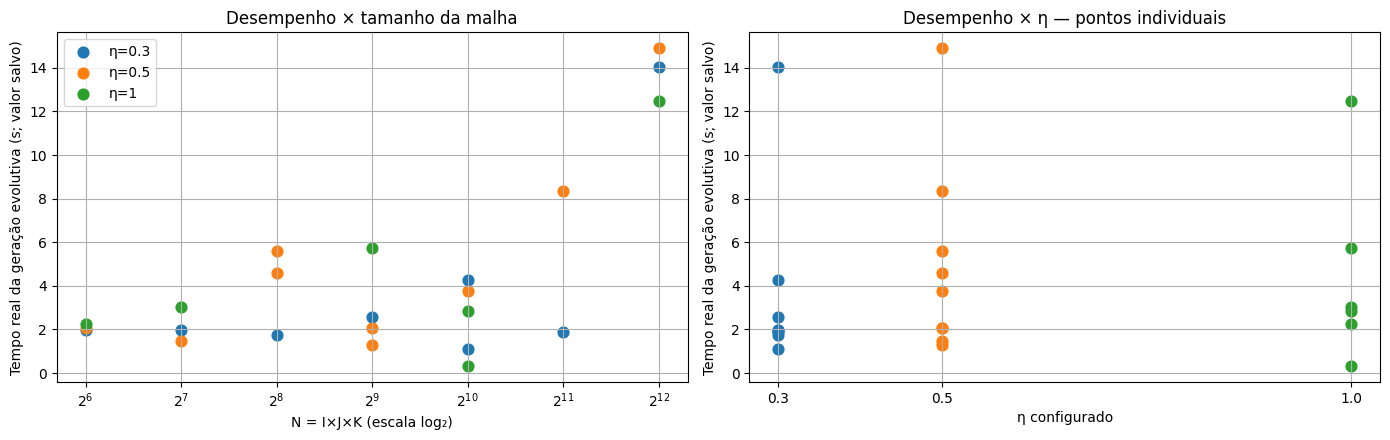

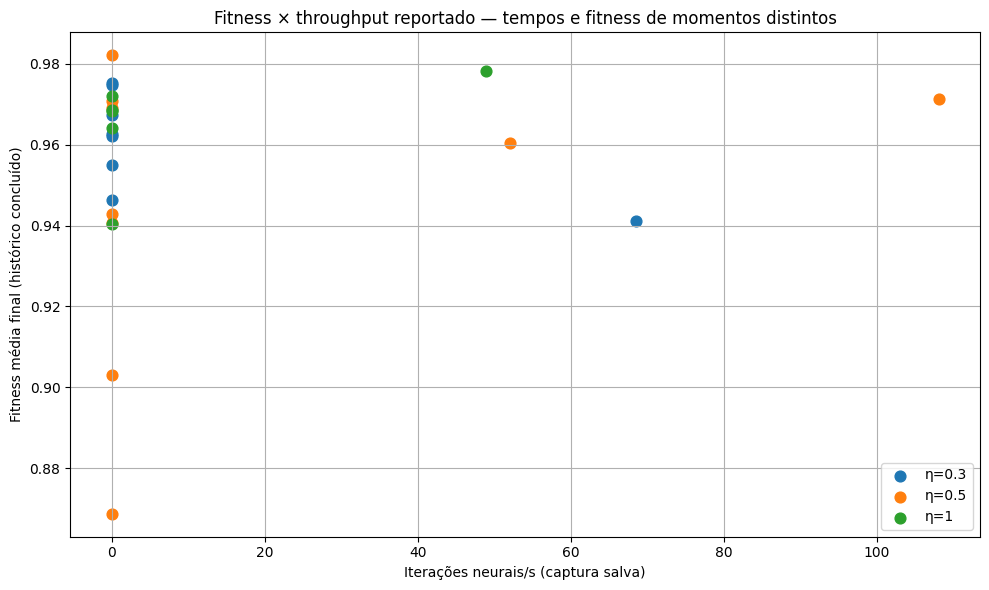

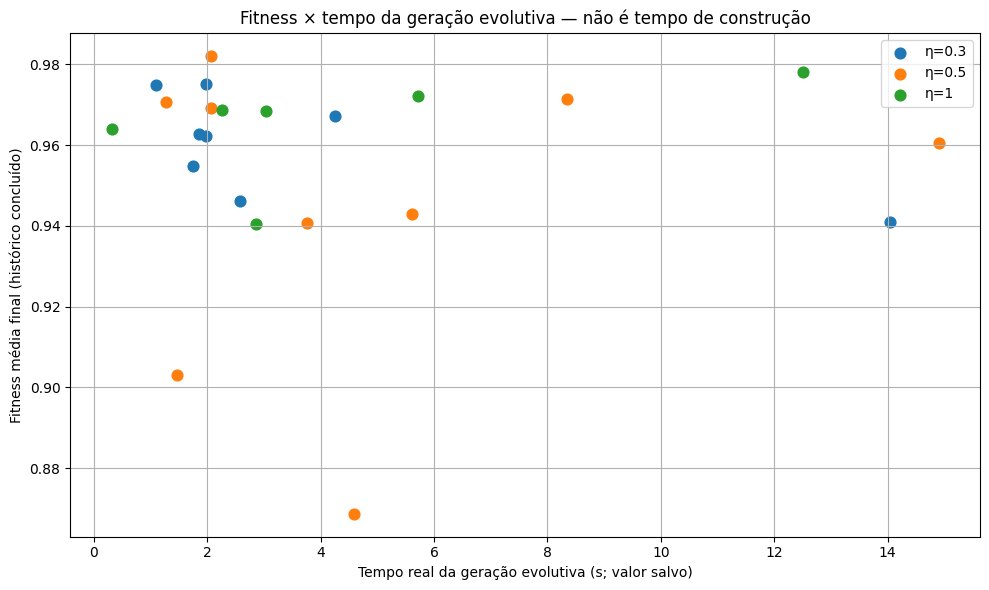

In [12]:
perf_cols = ['geometry','N','eta','completed_generations','performance_snapshot_generation',
             'neural_iterations_per_second_snapshot','generation_real_time_seconds_snapshot']
if summary.empty:
    print('Sem arquivos válidos para desempenho.')
else:
    perf = summary[perf_cols].copy()
    display(perf.sort_values(['N','geometry','eta']).rename(columns={'generation_real_time_seconds_snapshot':'tempo_real_geracao_evolutiva_s_snapshot', 'performance_snapshot_generation':'geracao_evolutiva_registrada'}))
    for field,label in [
        ('neural_iterations_per_second_snapshot','Iterações neurais/s (valor salvo)'),
        ('generation_real_time_seconds_snapshot','Tempo real da geração evolutiva (s; valor salvo)')]:
        values=summary.dropna(subset=[field]);
        if values.empty:
            print('Sem medições disponíveis:',label)
            continue
        fig,axes=plt.subplots(1,2,figsize=(14,4.5))
        for eta, part in values.groupby('eta'):
            part=part.sort_values('N')
            axes[0].scatter(part.N,part[field],s=60,label=f'η={eta:g}')
            axes[1].scatter(part.eta,part[field],s=60,label=f'η={eta:g}')
        axes[0].set_xscale('log',base=2)
        axes[0].set_xlabel('N = I×J×K (escala log₂)')
        axes[1].set_xlabel('η configurado')
        axes[1].set_xticks(sorted(ETA_CODES.values()))
        axes[0].set_ylabel(label);axes[1].set_ylabel(label)
        axes[0].set_title('Desempenho × tamanho da malha')
        axes[1].set_title('Desempenho × η — pontos individuais')
        axes[0].legend()
        plt.tight_layout();plt.show()

    if summary['neural_iterations_per_second_snapshot'].notna().any():
        fig, ax=plt.subplots(figsize=(10,6))
        for eta,part in summary.dropna(subset=['neural_iterations_per_second_snapshot']).groupby('eta'):
            ax.scatter(part.neural_iterations_per_second_snapshot,part.fitness_mean_final,
                       s=60,label=f'η={eta:g}')
        ax.set_xlabel('Iterações neurais/s (captura salva)')
        ax.set_ylabel('Fitness média final (histórico concluído)')
        ax.set_title('Fitness × throughput reportado — tempos e fitness de momentos distintos')
        ax.legend();plt.tight_layout();plt.show()
    if summary['generation_real_time_seconds_snapshot'].notna().any():
        fig,ax=plt.subplots(figsize=(10,6))
        for eta,part in summary.dropna(subset=['generation_real_time_seconds_snapshot']).groupby('eta'):
            ax.scatter(part.generation_real_time_seconds_snapshot,part.fitness_mean_final,
                       s=60,label=f'η={eta:g}')
        ax.set_xlabel('Tempo real da geração evolutiva (s; valor salvo)')
        ax.set_ylabel('Fitness média final (histórico concluído)')
        ax.set_title('Fitness × tempo da geração evolutiva — não é tempo de construção')
        ax.legend();plt.tight_layout();plt.show()


### Comparação pareada de desempenho entre valores de η

Tabela de diferenças observadas na **mesma geometria**. Sinais positivos significam valores maiores para o primeiro η, mas não indicam causalidade. Ausências permanecem `NaN`.

In [13]:
if not summary.empty:
    for metric in ['neural_iterations_per_second_snapshot','generation_real_time_seconds_snapshot']:
        piv=summary.pivot_table(index=['I','J','K','N','geometry'],columns='eta',values=metric,aggfunc='first')
        if piv.empty:
            print('Sem dados:',metric);continue
        out=piv.copy()
        for left,right in [(0.5,0.3),(1.0,0.5),(1.0,0.3)]:
            if left in piv.columns and right in piv.columns:
                out[f'Δ {left:g} − {right:g}']=piv[left]-piv[right]
        print('Tempo real da geração evolutiva (s; valor salvo)' if metric == 'generation_real_time_seconds_snapshot' else 'Iterações neurais/s (valor salvo)')
        display(out.reset_index())


Iterações neurais/s (valor salvo)


eta,I,J,K,N,geometry,0.3,0.5,1.0,Δ 0.5 − 0.3,Δ 1 − 0.5,Δ 1 − 0.3
0,4,4,4,64,4×4×4,0.0,0.0,0.0,0.0,0.0,0.0
1,8,4,4,128,8×4×4,0.0,0.0,0.0,0.0,0.0,0.0
2,8,8,4,256,8×8×4,0.0,0.0,NaN,0.0,NaN,NaN
3,8,8,8,512,8×8×8,0.0,0.0,0.0,0.0,0.0,0.0
4,16,4,4,256,16×4×4,NaN,0.0,NaN,NaN,NaN,NaN
5,16,8,4,512,16×8×4,NaN,0.0,NaN,NaN,NaN,NaN
6,16,8,8,1024,16×8×8,0.0,NaN,0.0,NaN,NaN,0.0
7,16,16,4,1024,16×16×4,0.0,0.0,0.0,0.0,0.0,0.0
8,16,16,8,2048,16×16×8,0.0,108.1,NaN,108.1,NaN,NaN
9,16,16,16,4096,16×16×16,68.6,52.1,49.0,-16.5,-3.1,-19.6


Tempo real da geração evolutiva (s; valor salvo)


eta,I,J,K,N,geometry,0.3,0.5,1.0,Δ 0.5 − 0.3,Δ 1 − 0.5,Δ 1 − 0.3
0,4,4,4,64,4×4×4,1.984,2.076,2.261,0.092,0.185,0.277
1,8,4,4,128,8×4×4,1.973,1.476,3.040,-0.497,1.564,1.067
2,8,8,4,256,8×8×4,1.742,4.581,NaN,2.839,NaN,NaN
3,8,8,8,512,8×8×8,2.576,1.281,5.715,-1.295,4.434,3.139
4,16,4,4,256,16×4×4,NaN,5.617,NaN,NaN,NaN,NaN
5,16,8,4,512,16×8×4,NaN,2.060,NaN,NaN,NaN,NaN
6,16,8,8,1024,16×8×8,1.102,NaN,0.313,NaN,NaN,-0.789
7,16,16,4,1024,16×16×4,4.255,3.769,2.862,-0.486,-0.907,-1.393
8,16,16,8,2048,16×16×8,1.864,8.338,NaN,6.474,NaN,NaN
9,16,16,16,4096,16×16×16,14.038,14.900,12.500,0.862,-2.400,-1.538


In [14]:
if not summary.empty:
    for field in ['agent_count','brain_density','mutation_probability','format_version','completed_generations']:
        print(field, 'valores distintos:',summary[field].dropna().unique().tolist()[:20])
    mismatch=summary.loc[summary.fitness_best_record+1e-8<summary.fitness_best_peak_in_history,
                          ['file','fitness_best_record','fitness_best_peak_in_history']]
    if not mismatch.empty:
        warnings.warn('Recorde histórico inferior ao máximo do histórico em alguns arquivos; confira o significado dos campos.')
        display(mismatch)
    summary.to_csv(EXPORT_DIR/'sim1_execucoes.csv',index=False)
    history.to_csv(EXPORT_DIR/'sim1_historicos.csv',index=False)
    summary[perf_cols].to_csv(EXPORT_DIR/'sim1_desempenho_snapshot.csv',index=False)
    pd.DataFrame({'missing_file':missing}).to_csv(EXPORT_DIR/'sim1_faltantes.csv',index=False)
    pd.DataFrame(errors,columns=['file','error']).to_csv(EXPORT_DIR/'sim1_erros.csv',index=False)
    print('CSV exportados para',EXPORT_DIR.resolve())
else:print('Sem dados para exportar.')


agent_count valores distintos: [100]
brain_density valores distintos: [0.3, 0.5, 1.0]
mutation_probability valores distintos: [0.001]
format_version valores distintos: [2]
completed_generations valores distintos: [96, 95, 94, 93, 100, 97, 101, 98, 99, 103]
CSV exportados para D:\Computacao\Godot\Games\Neurons\neurons-gpu\reader\outputs_sim1


### Interpretação das métricas

- **Fitness média final**: média populacional da **última geração concluída**.
- **Melhor fitness final**: melhor indivíduo da última geração concluída.
- **Melhor fitness absoluta histórica**: `evolution.best_agent_fitness`; não confundir com `best_agent_score` (score pode ter definição diferente).
- **Melhor fitness média histórica**: `evolution.best_mean_fitness`.
- **Área média da fitness**: média aritmética dos valores históricos; é equivalente à área discreta normalizada para comparações com mesmo número de gerações.
- **Convergência**: primeira ocorrência do limiar na fitness média; não exige permanência acima do limiar.
- **Diversidade genética**: métrica fornecida pela própria simulação; sua definição/normalização depende do código do Neurons.
- **Genomas distintos**: comparação exata do conteúdo serializado dos genomas finais, não uma distância genética.

Com apenas uma execução por configuração, não use barras de erro inventadas nem testes de significância; as diferenças observadas misturam efeitos paramétricos e aleatoriedade. Registre também semente, versão de código e eventuais mudanças de implementação fora do `.neuronsim`.
- **Iterações neurais/s e tempo real da geração evolutiva**: extraídos apenas do texto `summary` no instante salvo. Não são médias históricas nem medidas isoladas de geração dos agentes.
- **Tempo de construção dos cérebros**: indisponível no `.neuronsim`; não foi inferido.
